In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries loaded successfully!")

All libraries loaded successfully!


In [2]:
# Load Dataset

df = pd.read_csv(
    "diabetic_data.csv",
    na_values="?",
    low_memory=False
)

print("Dataset Loaded Successfully")
print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully
Dataset Shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
# data information chevking
df.info()
# printinging on Dataset Shape
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [7]:
#checking for missing values & correcting the Missing Values
missing_values = df.isnull().sum()

missing_values = missing_values[
    missing_values > 0
].sort_values(ascending=False)

missing_values

#working on Missing Value Percentage

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_percentage = missing_percentage[
    missing_percentage > 0
].sort_values(ascending=False)

missing_percentage



weight               96.858479
max_glu_serum        94.746772
A1Cresult            83.277322
medical_specialty    49.082208
payer_code           39.557416
race                  2.233555
diag_3                1.398306
diag_2                0.351787
diag_1                0.020636
dtype: float64

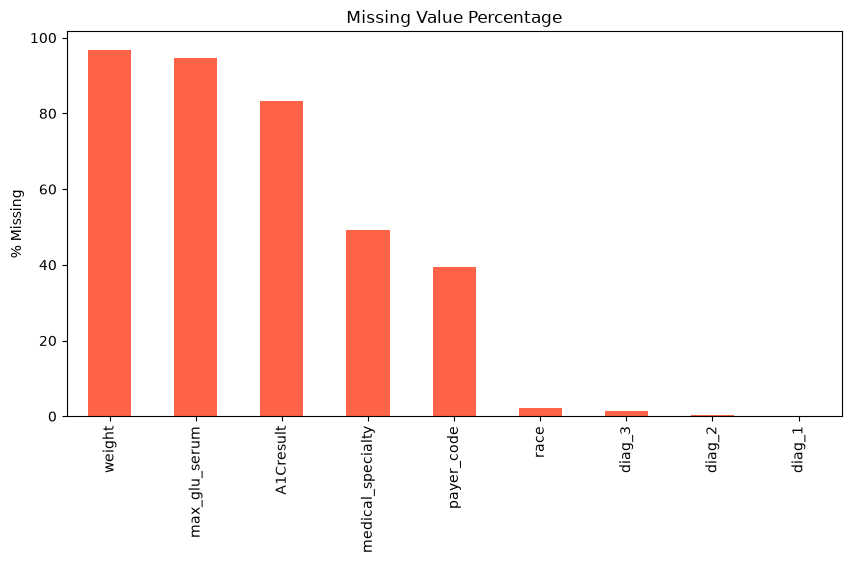

In [8]:
# printing Missing Values Graph
plt.figure(figsize=(10, 5))

missing_percentage.plot(
    kind="bar",
    color="tomato"
)

plt.title("Missing Value Percentage")
plt.ylabel("% Missing")

plt.show()

In [ ]:
# checking for any Duplicate values

duplicates = df.duplicated().sum()
print("Duplicate Rows:", duplicates)

# Target Variable Analysis from the data set
df["readmitted"].value_counts()

Duplicate Rows: 0


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

C:\Users\lavan\AppData\Local\Temp\ipykernel_29352\3571084459.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


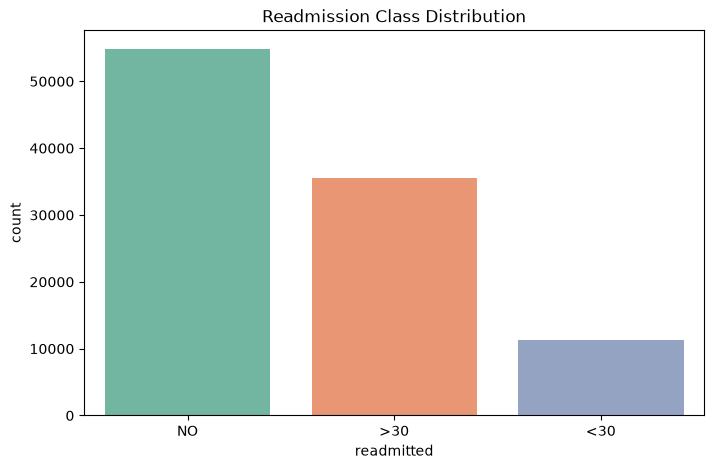

In [11]:
#Class Distribution Graph

plt.figure(figsize=(8,5))

sns.countplot(
    x="readmitted",
    data=df,
    palette="Set2"
)

plt.title("Readmission Class Distribution")

plt.show()

In [12]:
#Class Imbalance Ratio:
counts = df["readmitted"].value_counts()

ratio = counts.max() / counts.min()

print("Imbalance Ratio:", round(ratio, 2))

Imbalance Ratio: 4.83


In [15]:
#working on the Feature Types
categorical_cols = df.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = df.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Features:", len(categorical_cols))
print("Numerical Features:", len(numerical_cols))

Categorical Features: 37
Numerical Features: 13


C:\Users\lavan\AppData\Local\Temp\ipykernel_29352\1652300908.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


Phase 2: Data Preprocessing

In [16]:
#Defining Features and Target - to Separate predictors (X) from the target (y).

# =====================================
# FEATURES AND TARGET
# =====================================

target = "readmitted"
X = df.drop(columns=[target])
y = df[target]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (101766, 49)
Target Shape: (101766,)


In [17]:
# we are removing Identifier Columns as these columns do not help prediction. (encounter_id ,patient_nbr)
# =====================================
# REMOVE ID COLUMNS
# =====================================

id_columns = [
    "encounter_id",
    "patient_nbr"
]
X = X.drop(columns=id_columns)
print("Shape After Removing IDs:")
print(X.shape)

Shape After Removing IDs:
(101766, 47)


In [18]:
#Training -Test Split (80:20) as per ou
#Assignment Requirement we need to ahve (- 80:20 split, Random seed, Maintain class distribution)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (81412, 47)
Testing Shape: (20354, 47)


In [19]:
#Verifying Class Distribution - as our assignemnt asked to maintain class distribution.
print("Original Distribution")
print(    y.value_counts(normalize=True))
print("\nTraining Distribution")
print(    y_train.value_counts(normalize=True))
print("\nTesting Distribution")
print(    y_test.value_counts(normalize=True))

Original Distribution
readmitted
NO     0.539119
>30    0.349282
<30    0.111599
Name: proportion, dtype: float64

Training Distribution
readmitted
NO     0.539122
>30    0.349285
<30    0.111593
Name: proportion, dtype: float64

Testing Distribution
readmitted
NO     0.539108
>30    0.349268
<30    0.111624
Name: proportion, dtype: float64


In [20]:
#Now we are Identifying Feature Types
#Different preprocessing for: Numerical columns, Categorical columns
import numpy as np
categorical_features = (
    X_train
    .select_dtypes(
        include=["object"]
    )
    .columns
    .tolist()
)
numerical_features = (
    X_train
    .select_dtypes(
        include=np.number
    )
    .columns
    .tolist()
)
print("Categorical Features:", len(categorical_features))
print("Numerical Features:", len(numerical_features))

Categorical Features: 36
Numerical Features: 11


C:\Users\lavan\AppData\Local\Temp\ipykernel_29352\2500866111.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  .select_dtypes(


In [21]:
#we are going to Import Preprocessing Classes
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

In [22]:
#Verifying on Numerical Pipeline -As some numerical features may have missing values. 
#We'll check Impute median, Scale using StandardScaler

numeric_transformer = Pipeline(
    steps=[ ( "imputer",
            SimpleImputer(
                strategy="median"   )   ),
        ( "scaler",
            StandardScaler()
        )   ] )

In [23]:
# Now on Categorical Pipeline. As Machine Learning models cannot understand text.
#We'll be Fill missing categories, One-Hot Encoding
categorical_transformer = Pipeline(
    steps=[( "imputer",
            SimpleImputer( strategy="most_frequent")  ),
        ( "encoder",
            OneHotEncoder(handle_unknown="ignore" ) ) ]
)

In [24]:
#Here we are Combining Both Pipelines (Numerical & categorical)
preprocessor = ColumnTransformer(
    transformers=[ ( "num",
            numeric_transformer,
            numerical_features),
        ( "cat",
            categorical_transformer,
            categorical_features ) ]
)
print("Preprocessor Created Successfully")

Preprocessor Created Successfully


In [25]:
#In Here Now We are Testing the Pipeline to check and ensuring preprocessing works before model training.
X_train_processed = preprocessor.fit_transform(    X_train)
X_test_processed = preprocessor.transform( X_test)
print("Processed Training Shape:",  X_train_processed.shape)
print(   "Processed Test Shape:",   X_test_processed.shape)

Processed Training Shape: (81412, 2368)
Processed Test Shape: (20354, 2368)


Phase 2 Summary
Data Preprocessing Completed
Preprocessing Steps:
 - Removed identifier columns
     encounter_id
     patient_nbr
     Performed train-test split
    Training set: 80%, Testing set: 20%
- Maintained class distribution using stratification
- Handled missing values
- Numerical features: Median imputation
- Categorical features: Most frequent imputation
- Encoded categorical variables using One-Hot Encoding
- Applied feature scaling using StandardScaler
- Implemented ColumnTransformer and Pipeline
- Prevented data leakage by fitting preprocessing only on the training data
- Output Shape After Preprocessing:
     Training Data: (81412, 2368); Testing Data: (20354, 2368)

Phase 3: Machine Learning Models

In [26]:
#Importing ML Models as per our assignment requirement.
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

In [28]:
# Import Evaluation Metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score
)
from sklearn.preprocessing import LabelEncoder

In [29]:
#Encode Target for Multiclass AUC

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(
y_train
)
y_test_encoded = label_encoder.transform(
y_test
)
print(label_encoder.classes_)

['<30' '>30' 'NO']


In [33]:
#Create Models Dictionary

models = {
"Logistic Regression":
LogisticRegression(
max_iter=2000,
random_state=42
),

"Decision Tree":
DecisionTreeClassifier(
random_state=42
),

"KNN":
KNeighborsClassifier(
n_neighbors=5
),

"Naive Bayes":
GaussianNB(),

"Random Forest":
RandomForestClassifier(
n_estimators=100,
random_state=42
)
}

In [34]:
def evaluate_model(
    model,
    X_train,
    X_test,
    y_train,
    y_test
):

    # Train model
    model.fit(
        X_train,
        y_train
    )

    # Predictions
    predictions = model.predict(
        X_test
    )

    # Probabilities
    probabilities = model.predict_proba(
        X_test
    )

    # Metrics
    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average="macro"
    )

    recall = recall_score(
        y_test,
        predictions,
        average="macro"
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="macro"
    )

    mcc = matthews_corrcoef(
        y_test,
        predictions
    )

    auc = roc_auc_score(
        y_test,
        probabilities,
        multi_class="ovr"
    )

    return [
        accuracy,
        auc,
        precision,
        recall,
        f1,
        mcc
    ]

In [35]:
results = []

In [36]:
#Logistic Regression

logistic_model = LogisticRegression(
max_iter=3000,
random_state=42
)
 
scores = evaluate_model(
logistic_model,
X_train_processed,
X_test_processed,
y_train_encoded,
y_test_encoded
)
 
results.append(
["Logistic Regression"] + scores
)
 
print("Logistic Regression Completed")

Logistic Regression Completed


In [37]:
#Decision Tree

decision_tree_model = DecisionTreeClassifier(
random_state=42
)
 
scores = evaluate_model(
decision_tree_model,
X_train_processed,
X_test_processed,
y_train_encoded,
y_test_encoded
)
 
results.append(
["Decision Tree"] + scores
)
 
print("Decision Tree Completed")

Decision Tree Completed


In [38]:
#KNN

knn_model = KNeighborsClassifier(
n_neighbors=5
)
 
scores = evaluate_model(
knn_model,
X_train_processed,
X_test_processed,
y_train_encoded,
y_test_encoded
)
 
results.append(
["KNN"] + scores
)
 
print("KNN Completed")

KNN Completed


In [39]:
#Create Dense Data Only for Naive Bayes

X_train_dense = X_train_processed.toarray()
X_test_dense = X_test_processed.toarray()
print("Dense Conversion Complete")

Dense Conversion Complete


In [40]:
#Naive Bayes

naive_bayes_model = GaussianNB()
scores = evaluate_model(
naive_bayes_model,
X_train_dense,
X_test_dense,
y_train_encoded,
y_test_encoded
)

results.append(
["Naive Bayes"] + scores
)
print("Naive Bayes Completed")

Naive Bayes Completed


In [41]:
#Random Forest

random_forest_model = RandomForestClassifier(
n_estimators=100,
random_state=42,
n_jobs=-1
)
scores = evaluate_model(
random_forest_model,
X_train_processed,
X_test_processed,
y_train_encoded,
y_test_encoded
)
results.append(
["Random Forest"] + scores
)
print("Random Forest Completed")

Random Forest Completed


In [46]:
#Trained Models in model/ Folder

import joblib
import os

os.makedirs("model", exist_ok=True)

joblib.dump(logistic_model,
            "model/logistic_regression.pkl")

joblib.dump(decision_tree_model,
            "model/decision_tree.pkl")

joblib.dump(knn_model,
            "model/knn.pkl")

joblib.dump(naive_bayes_model,
            "model/naive_bayes.pkl")

joblib.dump(random_forest_model,
            "model/random_forest.pkl")

print("All models saved successfully!")

All models saved successfully!


In [47]:
#Saveing Trained Models" cell

# =====================================
# CREATE test_data.csv
# =====================================

test_data = X_test.copy()
test_data["readmitted"] = y_test
test_data.to_csv(
"test_data.csv",
index=False
)
print("test_data.csv created successfully!")

test_data.csv created successfully!


In [48]:
test_data.head()

,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
8705,Caucasian,Male,[60-70),NaN,1,1,7,5,NaN,Family/GeneralPractice,...,No,No,No,No,No,No,No,No,No,NO
31602,AfricanAmerican,Female,[80-90),NaN,6,1,17,6,NaN,Family/GeneralPractice,...,No,Steady,No,No,No,No,No,No,Yes,<30
100564,Caucasian,Male,[90-100),NaN,1,3,7,8,MC,NaN,...,No,Steady,Steady,No,No,No,No,Ch,Yes,NO
19157,Caucasian,Female,[40-50),NaN,1,1,7,2,NaN,InternalMedicine,...,No,No,No,No,No,No,No,No,Yes,NO
59372,Caucasian,Male,[50-60),NaN,2,1,1,7,NaN,Gastroenterology,...,No,No,No,No,No,No,No,No,No,>30


In [49]:
# =====================================
# CREATE OUTPUTS FOLDER
# =====================================

import os

os.makedirs(
    "outputs",
    exist_ok=True
)
print("outputs folder created successfully!")

outputs folder created successfully!


In [50]:
# =====================================
# SAVE RESULTS TABLE
# =====================================

results_df.to_csv(
    "outputs/model_comparison_results.csv",
    index=False
)

print("Results CSV saved successfully!")

Results CSV saved successfully!


In [42]:
#Create Results Table
results_df = pd.DataFrame(
results,
columns=[
"ML Model",
"Accuracy",
"AUC",
"Precision",
"Recall",
"F1 Score",
"MCC"
]
)
results_df

,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.574334,0.647635,0.472338,0.400242,0.380762,0.180412
1,Decision Tree,0.500491,0.550062,0.394848,0.392539,0.393089,0.116165
2,KNN,0.506682,0.583635,0.404437,0.398733,0.400039,0.123583
3,Naive Bayes,0.136533,0.505845,0.372699,0.340350,0.109401,0.017845
4,Random Forest,0.584750,0.657041,0.534800,0.404514,0.380382,0.199940


In [43]:
#Round Values
results_df = results_df.round(4)
results_df

,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.5743,0.6476,0.4723,0.4002,0.3808,0.1804
1,Decision Tree,0.5005,0.5501,0.3948,0.3925,0.3931,0.1162
2,KNN,0.5067,0.5836,0.4044,0.3987,0.4000,0.1236
3,Naive Bayes,0.1365,0.5058,0.3727,0.3404,0.1094,0.0178
4,Random Forest,0.5847,0.6570,0.5348,0.4045,0.3804,0.1999


In [44]:
#Save Results CSV

results_df.to_csv(
"model_comparison_results.csv",
index=False
)
print("Results Saved")

Results Saved


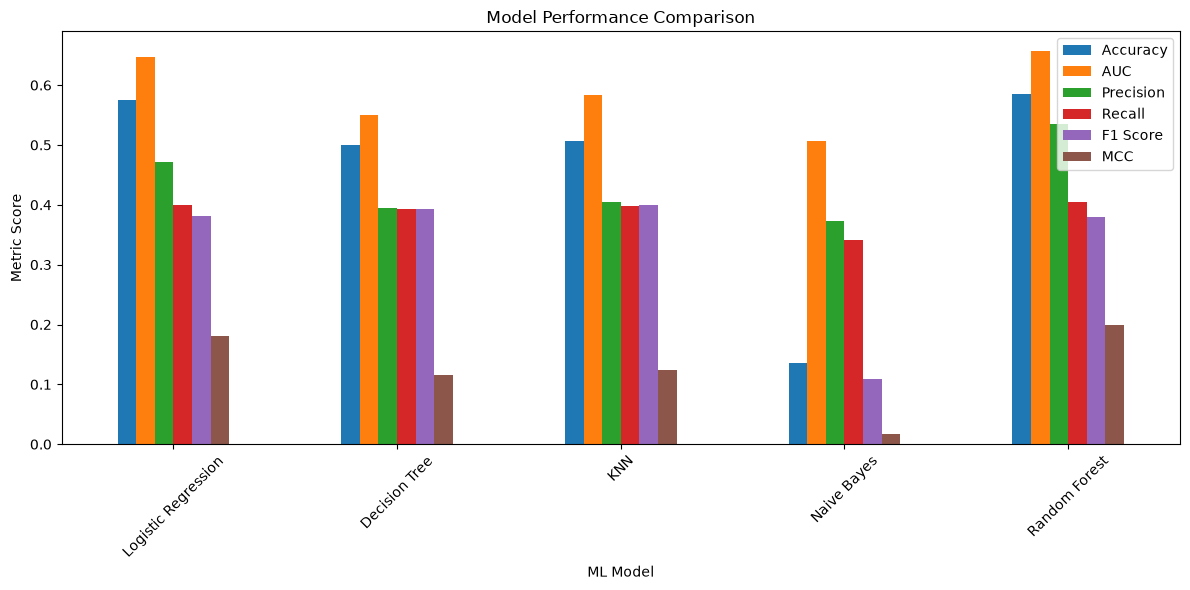

In [45]:
#Assignment Visualization

import matplotlib.pyplot as plt
metrics = [
"Accuracy",
"AUC",
"Precision",
"Recall",
"F1 Score",
"MCC"
]
results_df.set_index(
"ML Model"
)[metrics].plot(
kind="bar",
figsize=(12,6)
)
plt.title(
"Model Performance Comparison"
)
plt.ylabel(
"Metric Score"
)
plt.xticks(
rotation=45
)
plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

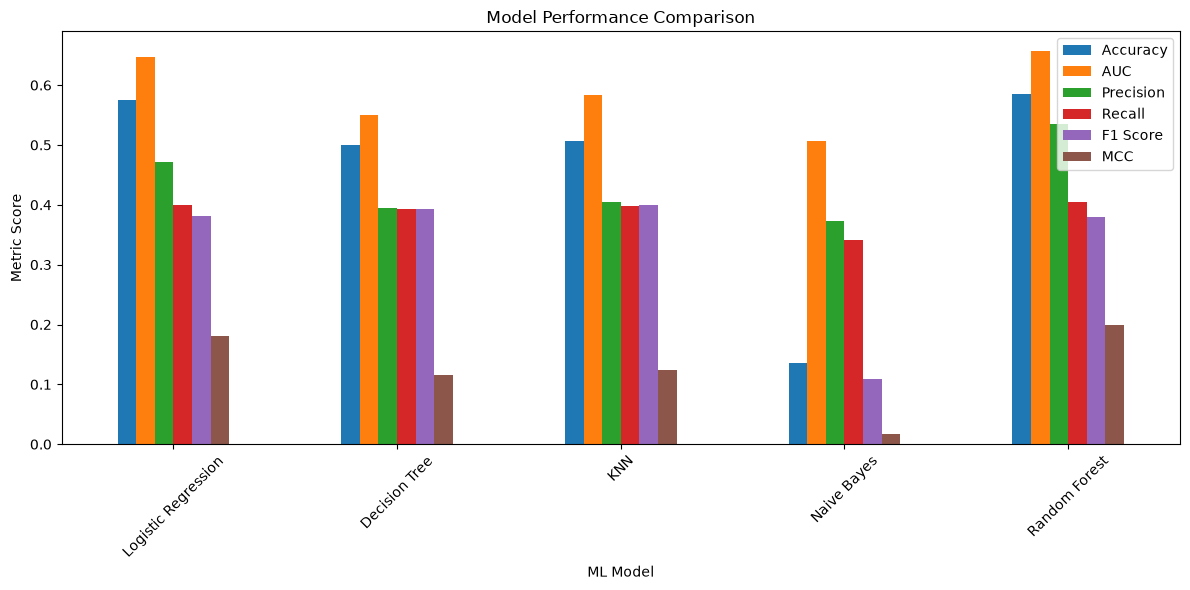

Graph saved successfully!


In [51]:
#TO Save Performance Graph
plt.figure(figsize=(12,6))
 
metrics = [
"Accuracy",
"AUC",
"Precision",
"Recall",
"F1 Score",
"MCC"
]
 
results_df.set_index(
"ML Model"
)[metrics].plot(
kind="bar",
figsize=(12,6)
)
 
plt.title(
"Model Performance Comparison"
)
 
plt.ylabel(
"Metric Score"
)
 
plt.xticks(
rotation=45
)
 
plt.tight_layout()
 
plt.savefig(
"outputs/model_comparison_graph.png",
bbox_inches="tight"
)
 
plt.show()
 
print("Graph saved successfully!")

In [52]:
#NOW VERIFIYING EVERYTHING
import os

print("Model Folder:")

print(os.listdir("model"))

print("\nOutputs Folder:")

print(os.listdir("outputs"))

Model Folder:
['.gitkeep', 'decision_tree.pkl', 'knn.pkl', 'logistic_regression.pkl', 'naive_bayes.pkl', 'random_forest.pkl']

Outputs Folder:
['model_comparison_graph.png', 'model_comparison_results.csv']
